# 09 · Quantum analysis of the circuits (Part B)

**No patient data is used.** Every analysis here is a property of the circuits themselves, evaluated over random
inputs (drawn from each circuit's real input range) and random parameters:

| Section | What it measures | Why a reviewer asks for it |
|---|---|---|
| 1 | The six modality VQCs + the meta-VQC, rebuilt exactly (checked against the parameter and gate counts in the report) | everything below uses these definitions |
| 2 | **Resource table**: qubits, layers, parameters, gates, two-qubit gates, depth, readout terms, measurement settings | cost of running the models on hardware |
| 3 | **Expressibility** (Sim et al. 2019, KL divergence to Haar) and **frame-potential ratio**, with and without entangling gates | how much of the state space each circuit can reach |
| 4 | **Entangling capability** (Meyer–Wallach Q), with and without entangling gates | whether the circuits actually create entanglement |
| 5 | **Barren-plateau check**: gradient variance vs number of qubits and layers | whether the circuits stay trainable as they grow |
| 6 | **Finite shots**: readout error vs number of shots | how many shots real hardware would need |
| 7 | **Noise robustness**: readout error vs depolarising noise level | how much hardware noise the outputs can tolerate |
| 8 | **Qiskit**: transpiled depth and two-qubit gate count on IBM heavy-hex hardware (fake backend) | real-device resource numbers |
| 9 | **Hardware emulation**: the methylation (4 qubits), proteomics and CNV (6) and gene-expression (9) circuits on noisy IBM fake backends | evidence beyond the noise-free simulator |

F1-score under noise and on emulated hardware needs the trained models and the patient data, so it is done in
Part C (cells added to the modality notebooks). Runtime ≈ 10–20 min on a Kaggle CPU (`FAST = True` → ≈ 3 min).

In [1]:
# ============================================================
# 0. SETTINGS (Qiskit is optional; sections 8-9 are skipped if it cannot be installed)
# ============================================================
import os, time, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

FAST = False                    # True = fewer samples, for a quick first run
RUN_QISKIT = True               # needs internet in the Kaggle settings (pip install qiskit qiskit-aer qiskit-ibm-runtime)
SEED = 42
N_PAIRS = 1000 if FAST else 5000          # state pairs for expressibility (Sim et al. use 5,000)
N_MW = 500 if FAST else 2000              # samples for entangling capability
N_GRAD = 200 if FAST else 500             # samples per point for gradient variance
N_NOISE, N_TRAJ = (16, 100) if FAST else (32, 300)
OUTPUT_DIR = os.path.join(os.environ.get("OUTPUT_DIR", "/kaggle/working" if os.path.isdir("/kaggle/working") else "."), "partB")
os.makedirs(OUTPUT_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

# ---- gene-expression circuit: the 9-qubit model of the shared-split run (03_gene_expression_shared_split) ----
# Graph printed by the edge cell of that notebook (12 edges, |r| >= 0.30, density 0.33).
GE_GENES = ["EIF3CL", "PABPC4", "FSTL5", "SCP2", "FAHD1", "BLACAT1", "VSTM2A", "CLVS1", "INPP5D"]   # qubit order
GE_EDGES = [(1, 3), (6, 7), (5, 6), (5, 7), (3, 8), (2, 6), (1, 8), (5, 8), (6, 8), (0, 2), (7, 8), (4, 5)]
GE_R = [0.71, 0.63, 0.56, 0.54, 0.51, 0.51, 0.47, -0.46, -0.46, -0.43, -0.37, 0.36]
assert GE_EDGES is not None and GE_R is not None and len(GE_EDGES) == len(GE_R), \
    "Paste GE_EDGES and GE_R from the edge printout of the shared-split gene notebook (see the instructions)."
print(f"Gene-expression circuit: {len(GE_GENES)} qubits, {len(GE_EDGES)} graph edges")

if RUN_QISKIT:
    try:
        import qiskit, qiskit_aer, qiskit_ibm_runtime  # noqa
    except ImportError:
        os.system("pip install -q qiskit qiskit-aer qiskit-ibm-runtime")
    try:
        import qiskit, qiskit_aer, qiskit_ibm_runtime  # noqa
        print("Qiskit", qiskit.__version__, "| Aer", qiskit_aer.__version__, "| ibm-runtime", qiskit_ibm_runtime.__version__)
    except Exception as e:
        RUN_QISKIT = False
        print("Qiskit not available, sections 8-9 will be skipped:", e)
print("Output:", OUTPUT_DIR)

Gene-expression circuit: 9 qubits, 12 graph edges


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
aiobotocore 2.26.0 requires python-dateutil<3.0.0,>=2.1, but you have python-dateutil 3.0.0 which is incompatible.
botocore 1.41.5 requires python-dateutil<3.0.0,>=2.1, but you have python-dateutil 3.0.0 which is incompatible.
holidays 0.107 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
google-cloud-bigquery 3.46.2 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
betterproto 2.0.0b7 requires pytho

Qiskit 2.6.1 | Aer 0.18.2 | ibm-runtime 0.51.0
Output: /kaggle/working/partB


In [2]:
# ============================================================
# 1. A SMALL EXACT STATEVECTOR SIMULATOR + THE SIX MODALITY CIRCUITS (AND THE META-VQC)
# Each circuit is a list of gates; every gate angle is a function of the input batch X and the parameter batch T,
# so the same description is used for expressibility, entanglement, gradients, noise and the Qiskit export.
# Conventions: RY(a) = exp(-i a Y/2), RZ(a) = exp(-i a Z/2), RZZ(a) = IsingZZ(a) = exp(-i a ZZ/2), Rot(p,t,w) = RZ(w) RY(t) RZ(p).
# ============================================================
import numpy as np

ENTANGLING = {"cnot", "cz", "rzz"}


class Circuit:
    def __init__(self, name, n, gates, n_params, sample_x, readout, head_obs, grad_param=0, layers=1, note=""):
        self.name, self.n, self.gates, self.n_params = name, n, gates, n_params
        self.sample_x, self.readout, self.head_obs = sample_x, readout, head_obs
        self.grad_param, self.layers, self.note = grad_param, layers, note

    def without_entanglers(self):
        return Circuit(self.name + " (no entangling gates)", self.n, [g for g in self.gates if g[0] not in ENTANGLING],
                       self.n_params, self.sample_x, self.readout, self.head_obs, self.grad_param, self.layers)

    def sample_params(self, B, rng):
        return rng.uniform(0, 2 * np.pi, (B, self.n_params))

    def rotation_params(self):
        # parameters that are plain rotation angles (the parameter-shift rule applies to them)
        return sorted({g[2].k for g in self.gates if g[2] is not None and hasattr(g[2], "k")})

    def probe_params(self, m=6):
        r = self.rotation_params()
        return [r[i] for i in np.unique(np.linspace(0, len(r) - 1, min(m, len(r))).round().astype(int))]

    # ---- simulation --------------------------------------------------------
    def states(self, X, T):
        B, n = len(X), self.n
        psi = np.zeros((B, 2 ** n), complex); psi[:, 0] = 1.0
        for g in self.gates:
            psi = apply_gate(psi, n, g, X, T)
        return psi

    def expvals(self, psi):
        p = np.abs(psi) ** 2
        return np.stack([p @ zsign(self.n, obs) for obs in self.readout], 1)

    # ---- static resources --------------------------------------------------
    def counts(self):
        one = sum(1 for g in self.gates if len(g[1]) == 1)
        two = sum(1 for g in self.gates if len(g[1]) == 2)
        by = {}
        for g in self.gates:
            by[g[0]] = by.get(g[0], 0) + 1
        return one, two, by

    def depth(self):
        lvl = [0] * self.n
        for g in self.gates:
            d = max(lvl[q] for q in g[1]) + 1
            for q in g[1]:
                lvl[q] = d
        return max(lvl)


_ZS = {}


def zsign(n, qubits):
    key = (n, tuple(qubits))
    if key not in _ZS:
        idx = np.arange(2 ** n); s = np.ones(2 ** n)
        for q in qubits:
            s *= 1 - 2 * ((idx >> (n - 1 - q)) & 1)
        _ZS[key] = s
    return _ZS[key]


def apply_gate(psi, n, g, X, T):
    kind, wires, ang = g[0], g[1], g[2]
    B = psi.shape[0]
    if kind in ("ry", "rz"):
        a = ang(X, T); q = wires[0]
        v = psi.reshape(B, 2 ** q, 2, 2 ** (n - q - 1))
        if kind == "ry":
            c, s = np.cos(a / 2)[:, None, None], np.sin(a / 2)[:, None, None]
            a0, a1 = v[:, :, 0, :], v[:, :, 1, :]
            out = np.empty_like(v); out[:, :, 0, :] = c * a0 - s * a1; out[:, :, 1, :] = s * a0 + c * a1
            return out.reshape(B, -1)
        e = np.exp(-0.5j * a)[:, None]
        return psi * np.where(zsign(n, (q,))[None, :] > 0, e, np.conj(e))
    if kind == "rzz":
        a = ang(X, T)
        return psi * np.exp(-0.5j * a[:, None] * zsign(n, wires)[None, :])
    if kind == "cz":
        return psi * zsign_cz(n, wires)[None, :]
    if kind == "cnot":
        c, t = wires
        v = psi.reshape((B,) + (2,) * n).copy()
        sl = [slice(None)] * (n + 1); sl[c + 1] = 1
        sub = v[tuple(sl)]
        ax = t + 1 if t < c else t
        v[tuple(sl)] = np.flip(sub, axis=ax)
        return v.reshape(B, -1)
    raise ValueError(kind)


_CZ = {}


def zsign_cz(n, wires):
    key = (n, tuple(wires))
    if key not in _CZ:
        idx = np.arange(2 ** n); a, b = wires
        _CZ[key] = np.where(((idx >> (n - 1 - a)) & 1) & ((idx >> (n - 1 - b)) & 1), -1.0, 1.0)
    return _CZ[key]


# ---- angle helpers ---------------------------------------------------------
xf = lambda i, f=lambda v: v: (lambda X, T: f(X[:, i]))          # data angle
def tf(k):                                                       # trainable angle (remembers its parameter index)
    f = lambda X, T: T[:, k]
    f.k = k
    return f


def rot(q, k):
    # PennyLane / StronglyEntangling Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi): 3 params k, k+1, k+2
    return [("rz", (q,), tf(k), "rot"), ("ry", (q,), tf(k + 1), "rot"), ("rz", (q,), tf(k + 2), "rot")]


def head_params(n_obs, k=4):
    return n_obs * k + k


# ---- input samplers (each circuit's real input range) ----------------------
def u_angles(n, lo=0.0, hi=np.pi):
    return lambda B, rng: rng.uniform(lo, hi, (B, n))


def build_proteomics(n=6, L=3):
    # AngleEmbedding RY((clip(z,+-3)+3)/6*pi) re-uploaded, StronglyEntangling layer (Rot + CNOT ring, range 1), <Z>
    g, k = [], 0
    for l in range(L):
        g += [("ry", (q,), xf(q)) for q in range(n)]
        for q in range(n):
            g += rot(q, k); k += 3
        g += [("cnot", (q, (q + 1) % n), None) for q in range(n)] if n > 2 else [("cnot", (0, 1), None)]
    return Circuit("Proteomics", n, g, k, u_angles(n), [(q,) for q in range(n)], n, grad_param=0, layers=L)


def build_methylation(n=4):
    # RY(pi/2 + arctan z), one trainable RY per qubit, no entangler, readout <Z_i> + <Z_i Z_j>
    g = [("ry", (q,), xf(q)) for q in range(n)] + [("ry", (q,), tf(q)) for q in range(n)]
    ro = [(q,) for q in range(n)] + [(i, j) for i in range(n) for j in range(i + 1, n)]
    smp = lambda B, rng: np.pi / 2 + np.arctan(rng.normal(0, 1, (B, n)))
    return Circuit("DNA methylation", n, g, n, smp, ro, len(ro), grad_param=0, layers=1,
                   note="no entangling gates: the state is always a product state")


# Gene-expression circuit = the 9-qubit model of the shared-split run (03_gene_expression_shared_split).
# GE_GENES / GE_EDGES / GE_R are set in the SETTINGS cell (pasted from the edge printout of that notebook).
if "GE_EDGES" not in globals() or GE_EDGES is None:      # stand-alone use of this file only
    GE_GENES = ["EIF3CL", "PABPC4", "FSTL5", "SCP2", "FAHD1", "BLACAT1", "VSTM2A", "CLVS1", "INPP5D"]
    GE_EDGES, GE_R = [(3, 7), (0, 5), (1, 4)], [0.40, 0.35, 0.31]          # placeholder graph for testing


def build_gene(n=None, edges=None, r=None, L=1):
    # graph-ZZ encoding: RY(x_i), IsingZZ(r_ij (pi - x_i)(pi - x_j)) on graph edges; Rot on each qubit; CNOT on edges
    n = len(GE_GENES) if n is None else n
    edges = GE_EDGES if edges is None else edges
    r = GE_R if r is None else r
    g, k = [], 0
    for l in range(L):
        g += [("ry", (q,), xf(q)) for q in range(n)]
        for (i, j), rr in zip(edges, r):
            g.append(("rzz", (i, j), (lambda i, j, rr: lambda X, T: rr * (np.pi - X[:, i]) * (np.pi - X[:, j]))(i, j, rr)))
        for q in range(n):
            g += rot(q, k); k += 3
        g += [("cnot", (i, j), None) for i, j in edges]
    return Circuit("Gene expression", n, g, k, u_angles(n), [(q,) for q in range(n)], n, grad_param=0, layers=L)


MI_EDGES = [(0, 1), (0, 4), (1, 5), (2, 5), (2, 6), (3, 5), (3, 7)]   # final partial-correlation graph (miRNA notebook)


def build_mirna(n=8, edges=MI_EDGES, L=1):
    # RY((z/3+1) pi/2); L x [Rot on each qubit, CZ on graph edges]; final Rot layer; <Z>
    g, k = [("ry", (q,), xf(q)) for q in range(n)], 0
    for l in range(L):
        for q in range(n):
            g += rot(q, k); k += 3
        g += [("cz", (i, j), None) for i, j in edges]
    for q in range(n):
        g += rot(q, k); k += 3
    return Circuit("miRNA", n, g, k, u_angles(n), [(q,) for q in range(n)], n, grad_param=0, layers=L)


def brick(n):
    return [(q, q + 1) for q in range(0, n - 1, 2)] + [(q, q + 1) for q in range(1, n - 1, 2)]


def build_snv(n=11, L=3, name="SNV", sampler=None):
    # per layer: RY(pi x) re-upload, RY(theta) + RZ(phi) on every qubit, CZ brickwork; <Z>
    g, k = [], 0
    for l in range(L):
        g += [("ry", (q,), xf(q, lambda v: np.pi * v)) for q in range(n)]
        for q in range(n):
            g += [("ry", (q,), tf(k)), ("rz", (q,), tf(k + 1))]; k += 2
        g += [("cz", e, None) for e in brick(n)]
    if sampler is None:
        def sampler(B, rng):   # 10 binary driver-gene indicators + TMB level in {0, 1/3, 2/3, 1}
            X = (rng.random((B, n)) < 0.25).astype(float)
            X[:, -1] = rng.integers(0, 4, B) / 3.0
            return X
    return Circuit(name, n, g, k, sampler, [(q,) for q in range(n)], n, grad_param=0, layers=L)


def build_meta(n=8, L=2):
    # meta-VQC of the fusion notebook: same circuit family as SNV, inputs = modality class probabilities in [0, 1]
    return build_snv(n, L, name="Meta-VQC (fusion)", sampler=lambda B, rng: rng.dirichlet(np.ones(4), (B, 2)).reshape(B, 8)[:, :n])


def build_cnv(n=6, L=1):
    # RY(a_i x_i) + RZZ(g_ij x_i x_j) on ring edges (trainable scales a, g), RY + RZ, CNOT ring, final RY;
    # readout <Z_i> + <Z_i Z_j> on ring edges. x = clip(z, +-3) * pi/6.
    ring = [(i, (i + 1) % n) for i in range(n)]
    g, k = [], 0
    for l in range(L):
        for i in range(n):
            g.append(("ry", (i,), (lambda i, k: lambda X, T: T[:, k] * X[:, i])(i, k))); k += 1
        for (i, j) in ring:
            g.append(("rzz", (i, j), (lambda i, j, k: lambda X, T: T[:, k] * X[:, i] * X[:, j])(i, j, k))); k += 1
        first_bias = k
        for i in range(n):
            g += [("ry", (i,), tf(k)), ("rz", (i,), tf(k + 1))]; k += 2
        g += [("cnot", e, None) for e in ring]
    for i in range(n):
        g.append(("ry", (i,), tf(k))); k += 1
    smp = lambda B, rng: np.clip(rng.normal(0, 1, (B, n)), -3, 3) * np.pi / 6
    c = Circuit("Copy number (CNV)", n, g, k, smp, [(i,) for i in range(n)] + ring, 2 * n, grad_param=first_bias, layers=L)
    n_scale = n + len(ring)

    def sample_params(B, rng):      # encoding scales a, g in [0, 2]; rotation angles in [0, 2 pi)
        T = rng.uniform(0, 2 * np.pi, (B, c.n_params)); T[:, :n_scale] = rng.uniform(0, 2, (B, n_scale)); return T
    c.sample_params = sample_params
    return c


def all_circuits():
    return [build_proteomics(), build_methylation(), build_gene(), build_mirna(), build_snv(), build_cnv(), build_meta()]


# values reported in the modality notebooks / report, used as a check
REPORTED = {"Proteomics": dict(total_params=82, gates=54), "DNA methylation": dict(total_params=48, gates=8),
            "Gene expression": dict(total_params=67, gates=2 * len(GE_GENES) + 2 * len(GE_EDGES)), "miRNA": dict(total_params=84, gates=31),
            "SNV": dict(total_params=114, gates=129), "Copy number (CNV)": dict(total_params=82, gates=36),
            "Meta-VQC (fusion)": dict(total_params=None, gates=None)}


def gate_count_rot_as_one(c):
    # the report counts Rot(phi, theta, omega) as one gate
    n_rot_parts = sum(1 for g in c.gates if len(g) > 3 and g[3] == "rot")
    return len(c.gates) - 2 * n_rot_parts // 3

In [3]:
# ============================================================
# 2. ANALYSIS FUNCTIONS
# ============================================================


def _chunks(total, size):
    for s in range(0, total, size):
        yield min(size, total - s)


def chunk_for(n):
    return max(50, min(2000, int(2 ** 21 / 2 ** n)))      # keeps each batch of states around 32 MB


def expressibility(c, n_pairs, rng, bins=75):
    # Sim et al. (2019): KL divergence between the fidelity distribution of pairs of circuit states (random inputs and
    # random parameters) and the Haar distribution P(F) = (N-1)(1-F)^(N-2). Lower = more expressive (closer to Haar).
    F = []
    for b in _chunks(n_pairs, chunk_for(c.n)):
        a = c.states(c.sample_x(b, rng), c.sample_params(b, rng))
        d = c.states(c.sample_x(b, rng), c.sample_params(b, rng))
        F.append(np.abs(np.sum(np.conj(a) * d, 1)) ** 2)
    F = np.concatenate(F)
    edges = np.linspace(0, 1, bins + 1); N = 2 ** c.n
    p = np.histogram(F, edges)[0] / len(F)
    q = (1 - edges[:-1]) ** (N - 1) - (1 - edges[1:]) ** (N - 1)
    m = p > 0
    return float(np.sum(p[m] * np.log(p[m] / np.maximum(q[m], 1e-300)))), F


def meyer_wallach(c, n_samples, rng):
    # entangling capability Q = 2 (1 - mean_k Tr(rho_k^2)); 0 = product states, 1 = maximal (e.g. GHZ-like)
    Q = []
    for b in _chunks(n_samples, chunk_for(c.n)):
        psi = c.states(c.sample_x(b, rng), c.sample_params(b, rng)); n = c.n; pur = 0.0
        for k in range(n):
            v = psi.reshape(b, 2 ** k, 2, 2 ** (n - k - 1)).transpose(0, 2, 1, 3).reshape(b, 2, -1)
            rho = v @ np.conj(v.transpose(0, 2, 1))
            pur = pur + np.real(np.sum(np.abs(rho) ** 2, axis=(1, 2)))
        Q.append(2 * (1 - pur / n))
    Q = np.concatenate(Q)
    return float(Q.mean()), float(Q.std())


def grad_variance(c, n_samples, rng, params=None, cost="local"):
    # variance over random inputs and parameters of dC/dtheta (exact parameter-shift rule), averaged over up to six
    # rotation angles spread across the circuit. Cost "local" = <Z_0>; "global" = <Z_0 Z_1 ... Z_{n-1}>.
    ks = c.probe_params() if params is None else params
    obs = (0,) if cost == "local" else tuple(range(c.n))
    zs = zsign(c.n, obs); V, M = [], []
    for k in ks:
        G = []
        for b in _chunks(n_samples, chunk_for(c.n)):
            X, T = c.sample_x(b, rng), c.sample_params(b, rng)
            Tp, Tm = T.copy(), T.copy(); Tp[:, k] += np.pi / 2; Tm[:, k] -= np.pi / 2
            ep = (np.abs(c.states(X, Tp)) ** 2) @ zs; em = (np.abs(c.states(X, Tm)) ** 2) @ zs
            G.append((ep - em) / 2)
        G = np.concatenate(G); V.append(G.var()); M.append(np.abs(G).mean())
    return float(np.mean(V)), float(np.mean(M))


def noisy_expvals(c, X, T, p, n_traj, rng, p2=None):
    # depolarising noise by quantum trajectories: after every gate, each qubit it acts on gets a random Pauli
    # (X, Y or Z, each with probability p/3) -- the standard unravelling of the single-qubit depolarising channel.
    # two-qubit gates use p2 per qubit (default 10 x p, typical of current hardware where 2-qubit errors dominate).
    p2 = 10 * p if p2 is None else p2
    B, n = len(X), c.n
    Xr, Tr = np.repeat(X, n_traj, 0), np.repeat(T, n_traj, 0)
    psi = np.zeros((len(Xr), 2 ** n), complex); psi[:, 0] = 1.0
    for g in c.gates:
        psi = apply_gate(psi, n, g, Xr, Tr)
        pe = p if len(g[1]) == 1 else p2
        if pe <= 0:
            continue
        for q in g[1]:
            r = rng.random(len(psi)); hit = r < pe
            if not hit.any():
                continue
            which = rng.integers(0, 3, hit.sum())          # 0 = X, 1 = Y, 2 = Z
            sub = psi[hit].reshape(hit.sum(), 2 ** q, 2, 2 ** (n - q - 1))
            out = sub.copy()
            xm, ym, zm = which == 0, which == 1, which == 2
            out[xm, :, 0, :], out[xm, :, 1, :] = sub[xm, :, 1, :], sub[xm, :, 0, :]
            out[ym, :, 0, :], out[ym, :, 1, :] = -1j * sub[ym, :, 1, :], 1j * sub[ym, :, 0, :]
            out[zm, :, 1, :] = -sub[zm, :, 1, :]
            psi[hit] = out.reshape(hit.sum(), -1)
    z = c.expvals(psi).reshape(B, n_traj, -1).mean(1)
    return z


def shot_expvals(c, psi, shots, rng):
    # finite measurement shots: sample bitstrings from |psi|^2, estimate every (diagonal) readout observable
    p = np.abs(psi) ** 2; p = p / p.sum(1, keepdims=True); out = []
    S = np.stack([zsign(c.n, o) for o in c.readout], 1)             # (2^n, n_obs)
    for row in p:
        cnt = rng.multinomial(shots, row)
        out.append(cnt @ S / shots)
    return np.array(out)

In [4]:
# ============================================================
# 3. CHECK: the rebuilt circuits reproduce the report (parameters and gate counts)
# ============================================================
CIRCS = all_circuits()
rows = []
for c in CIRCS:
    rep = REPORTED[c.name]; tot = c.n_params + head_params(len(c.readout))
    rows.append({"circuit": c.name, "qubits": c.n, "quantum_params": c.n_params, "head_params": head_params(len(c.readout)),
                 "total_params": tot, "report_total": rep["total_params"],
                 "gates_Rot_as_1": gate_count_rot_as_one(c), "report_gates": rep["gates"]})
chk = pd.DataFrame(rows); display(chk)
ok = all((pd.isna(r.report_total) or r.total_params == r.report_total) and (pd.isna(r.report_gates) or r.gates_Rot_as_1 == r.report_gates)
         for r in chk.itertuples())
print("All parameter and gate counts match the report:", ok)

# optional: compare the gene-expression circuit with the PennyLane circuit of the gene notebook
try:
    import pennylane as qml
    c = build_gene(); X = c.sample_x(3, rng); T = c.sample_params(1, rng)
    dev = qml.device("default.qubit", wires=c.n)
    @qml.qnode(dev)
    def pl(x, th):
        for i in range(c.n): qml.RY(x[i], wires=i)
        for (i, j), r in zip(GE_EDGES, GE_R): qml.IsingZZ(r * (np.pi - x[i]) * (np.pi - x[j]), wires=[i, j])
        for i in range(c.n): qml.Rot(th[3 * i], th[3 * i + 1], th[3 * i + 2], wires=i)
        for i, j in GE_EDGES: qml.CNOT(wires=[i, j])
        return [qml.expval(qml.PauliZ(i)) for i in range(c.n)]
    z_pl = np.array([pl(x, T[0]) for x in X]); z_me = c.expvals(c.states(X, np.repeat(T, 3, 0)))
    print("Gene circuit vs PennyLane, max |<Z> difference|:", float(np.abs(z_pl - z_me).max()))
except Exception as e:
    print("PennyLane check skipped:", type(e).__name__)

,circuit,qubits,quantum_params,head_params,total_params,report_total,gates_Rot_as_1,report_gates
0,Proteomics,6,54,28,82,82.0,54,54.0
1,DNA methylation,4,4,44,48,48.0,8,8.0
2,Gene expression,9,27,40,67,67.0,42,42.0
3,miRNA,8,48,36,84,84.0,31,31.0
4,SNV,11,66,48,114,114.0,129,129.0
5,Copy number (CNV),6,30,52,82,82.0,36,36.0
6,Meta-VQC (fusion),8,32,36,68,NaN,62,NaN


All parameter and gate counts match the report: True
PennyLane check skipped: ModuleNotFoundError


In [5]:
# ============================================================
# 4. RESOURCE TABLE (logical circuit, before compiling to hardware)
# Depth counts each RY / RZ / CNOT / CZ / RZZ as one layer step (Rot = RZ RY RZ = 3 steps).
# All readout observables are products of Z, so one measurement setting (computational basis) gives all of them.
# Shots for a standard error <= 0.01 on every readout value: 1 / 0.01^2 = 10,000 in the worst case (<Z> = 0).
# ============================================================
rows = []
for c in CIRCS:
    one, two, by = c.counts()
    two_types = ", ".join(f"{k.upper()} {v}" for k, v in by.items() if k in ENTANGLING) or "none"
    rows.append({"circuit": c.name, "qubits": c.n, "layers": c.layers, "quantum_params": c.n_params,
                 "total_params": c.n_params + head_params(len(c.readout)), "gates_Rot_as_1": gate_count_rot_as_one(c),
                 "one_qubit_gates": one, "two_qubit_gates": two, "two_qubit_types": two_types, "depth": c.depth(),
                 "readout_terms": len(c.readout), "measurement_settings": 1, "shots_SE_0.01": 10000,
                 "statevector_size": 2 ** c.n})
RES = pd.DataFrame(rows); RES.to_csv(os.path.join(OUTPUT_DIR, "B1_resources.csv"), index=False); display(RES)

,circuit,qubits,layers,quantum_params,total_params,gates_Rot_as_1,one_qubit_gates,two_qubit_gates,two_qubit_types,depth,readout_terms,measurement_settings,shots_SE_0.01,statevector_size
0,Proteomics,6,3,54,82,54,72,18,CNOT 18,30,6,1,10000,64
1,DNA methylation,4,1,4,48,8,8,0,none,2,10,1,10000,16
2,Gene expression,9,1,27,67,42,36,24,"RZZ 12, CNOT 12",16,9,1,10000,512
3,miRNA,8,1,48,84,31,56,7,CZ 7,12,8,1,10000,256
4,SNV,11,3,66,114,129,99,30,CZ 30,15,11,1,10000,2048
5,Copy number (CNV),6,1,30,82,36,24,12,"RZZ 6, CNOT 6",16,12,1,10000,64
6,Meta-VQC (fusion),8,2,32,68,62,48,14,CZ 14,10,8,1,10000,256


Proteomics             done (2s)
DNA methylation        done (0s)
Gene expression        done (12s)
miRNA                  done (5s)
SNV                    done (123s)
Copy number (CNV)      done (1s)
Meta-VQC (fusion)      done (6s)


,circuit,variant,qubits,expressibility_KL,frame_potential_ratio,entangling_capability_Q,Q_sd
0,Proteomics,with entangling gates,6,0.0029,0.9909,0.9431,0.0287
1,Proteomics,without entangling gates,6,0.2572,3.1042,0.0000,0.0000
2,DNA methylation,with entangling gates,4,0.6477,2.6167,0.0000,0.0000
3,Gene expression,with entangling gates,9,0.0982,2.9141,0.7708,0.1027
4,Gene expression,without entangling gates,9,0.2200,6.5759,-0.0000,0.0000
5,miRNA,with entangling gates,8,0.0759,2.2949,0.4936,0.1523
6,miRNA,without entangling gates,8,0.2259,5.7464,-0.0000,0.0000
7,SNV,with entangling gates,11,0.0545,5.4287,0.6532,0.1090
8,SNV,without entangling gates,11,0.2353,16.0506,-0.0000,0.0000
9,Copy number (CNV),with entangling gates,6,0.0310,1.3125,0.8527,0.1050


Methylation has no entangling gates, so Q = 0 by construction (its state is always a product state).


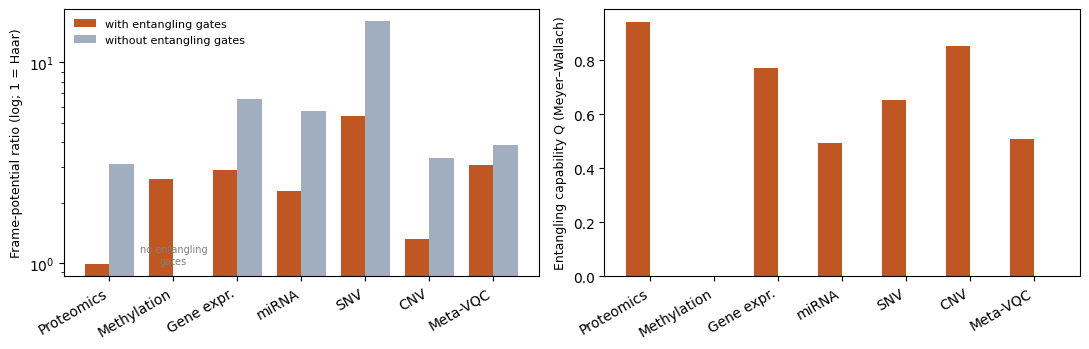

In [6]:
# ============================================================
# 5. EXPRESSIBILITY AND ENTANGLING CAPABILITY, WITH AND WITHOUT ENTANGLING GATES
# Expressibility (KL to Haar, lower = more expressive) loses resolution above ~8 qubits because the Haar fidelity
# distribution collapses into the first histogram bin; the frame-potential ratio E[F^2] / E_Haar[F^2] (1 = Haar-like,
# larger = less expressive) stays informative, so both are reported.
# ============================================================
def frame_ratio(F, n):
    N = 2 ** n; return float(np.mean(F ** 2) / (2 / (N * (N + 1))))


rows, FID = [], {}
for c in CIRCS:
    t0 = time.time()
    variants = [("with entangling gates", c)]
    if any(g[0] in ENTANGLING for g in c.gates):
        variants.append(("without entangling gates", c.without_entanglers()))
    for lab, cc in variants:
        e, F = expressibility(cc, N_PAIRS, rng); q, qs = meyer_wallach(cc, N_MW, rng); FID[(c.name, lab)] = F
        rows.append({"circuit": c.name, "variant": lab, "qubits": c.n, "expressibility_KL": e,
                     "frame_potential_ratio": frame_ratio(F, c.n), "entangling_capability_Q": q, "Q_sd": qs})
    print(f"{c.name:22s} done ({time.time() - t0:.0f}s)")
EXP = pd.DataFrame(rows); EXP.to_csv(os.path.join(OUTPUT_DIR, "B2_expressibility_entanglement.csv"), index=False)
display(EXP.round(4))
print("Methylation has no entangling gates, so Q = 0 by construction (its state is always a product state).")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
names = [c.name for c in CIRCS]; x = np.arange(len(names))
for ax, col, lab in [(axes[0], "frame_potential_ratio", "Frame-potential ratio (log; 1 = Haar)"),
                     (axes[1], "entangling_capability_Q", "Entangling capability Q (Meyer–Wallach)")]:
    for j, (var, colr) in enumerate([("with entangling gates", "#c05621"), ("without entangling gates", "#a0aec0")]):
        v = [EXP[(EXP.circuit == n) & (EXP.variant == var)][col].values for n in names]
        v = [a[0] if len(a) else np.nan for a in v]
        ax.bar(x + (j - 0.5) * 0.38, v, 0.38, color=colr, label=var)
    ax.set_xticks(x, [n.replace(" (fusion)", "").replace("Copy number (CNV)", "CNV").replace("DNA methylation", "Methylation")
                      .replace("Gene expression", "Gene expr.") for n in names], rotation=30, ha="right")
    ax.set_ylabel(lab, fontsize=9)
    if col == "frame_potential_ratio":
        ax.set_yscale("log")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
axes[0].text(1, axes[0].get_ylim()[0] * 1.15, "no entangling\ngates", ha="center", fontsize=7, color="grey")
fig.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "figB2_expressibility_entanglement.png"), dpi=200); plt.show()

Proteomics (L=3)             done
Methylation (no entangler)   done
Gene expr. (graph-ZZ)        done
miRNA (CZ graph)             done
SNV (L=3)                    done
CNV (RZZ ring)               done
Proteomics (n=6)             (vs layers) done
SNV (n=11)                   (vs layers) done


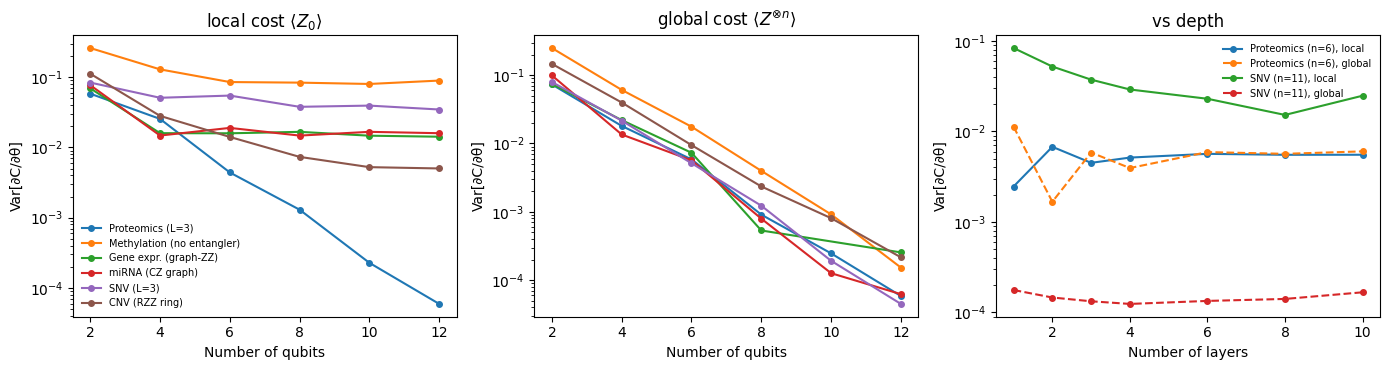

Gradient variance of the circuits as used in the study:


,circuit,qubits,local_grad_var,local_mean_abs,global_grad_var,global_mean_abs
0,Proteomics,6,0.00506,0.04710,0.00578,0.04928
1,DNA methylation,4,0.12248,0.15684,0.06187,0.16218
2,Gene expression,9,0.01457,0.03443,0.00000,0.00000
3,miRNA,8,0.01190,0.03085,0.00088,0.01262
4,SNV,11,0.03661,0.06556,0.00012,0.00493
5,Copy number (CNV),6,0.01339,0.04757,0.00999,0.06521
6,Meta-VQC (fusion),8,0.04978,0.07734,0.00082,0.01071


In [7]:
# ============================================================
# 6. BARREN-PLATEAU CHECK: variance of the gradient of one rotation angle, over random inputs and parameters
# averaged over up to six rotation angles spread across each circuit.
# (a) each circuit family vs number of qubits at its real depth; (b) proteomics / SNV families vs number of layers.
# Local cost = <Z_0>; global cost = <Z_0 ... Z_{n-1}>. Exponential decay with qubits = barren plateau.
# ============================================================
def chain(n): return [(i, i + 1) for i in range(n - 1)]


FAMILIES = {
    "Proteomics (L=3)": lambda n: build_proteomics(n, 3),
    "Methylation (no entangler)": lambda n: build_methylation(n),
    "Gene expr. (graph-ZZ)": lambda n: build_gene(n, chain(n), [0.4] * (n - 1)),
    "miRNA (CZ graph)": lambda n: build_mirna(n, chain(n)),
    "SNV (L=3)": lambda n: build_snv(n, 3),
    "CNV (RZZ ring)": lambda n: build_cnv(n),
}
QUBITS = [2, 4, 6, 8, 10] if FAST else [2, 4, 6, 8, 10, 12]
rows = []
for fam, make in FAMILIES.items():
    for n in QUBITS:
        c = make(n)
        for cost in ["local", "global"]:
            v, m = grad_variance(c, N_GRAD, rng, cost=cost)
            rows.append({"family": fam, "qubits": n, "layers": c.layers, "cost": cost, "grad_variance": v, "mean_abs_grad": m})
    print(f"{fam:28s} done")
LAYERS = [1, 2, 4, 6, 8] if FAST else [1, 2, 3, 4, 6, 8, 10]
for fam, make in {"Proteomics (n=6)": lambda L: build_proteomics(6, L), "SNV (n=11)": lambda L: build_snv(11, L)}.items():
    for L in LAYERS:
        c = make(L)
        for cost in ["local", "global"]:
            v, m = grad_variance(c, N_GRAD, rng, cost=cost)
            rows.append({"family": fam, "qubits": c.n, "layers": L, "cost": cost, "grad_variance": v, "mean_abs_grad": m})
    print(f"{fam:28s} (vs layers) done")
BP = pd.DataFrame(rows)
# values below 1e-20 are exact zeros: the probed angles cannot change the global parity <Z...Z> after the CNOT
# network (a structural property, not a numerical problem); they are marked and left out of the plot.
BP["structural_zero"] = BP.grad_variance < 1e-20
BP.to_csv(os.path.join(OUTPUT_DIR, "B3_barren_plateau.csv"), index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, cost in zip(axes[:2], ["local", "global"]):
    for fam in FAMILIES:
        d = BP[(BP.family == fam) & (BP.cost == cost) & ~BP.structural_zero]
        ax.semilogy(d.qubits, d.grad_variance, "o-", label=fam, ms=4)
    ax.set_xlabel("Number of qubits"); ax.set_ylabel("Var[∂C/∂θ]"); ax.set_title(f"{cost} cost " + (r"$\langle Z_0\rangle$" if cost == "local" else r"$\langle Z^{\otimes n}\rangle$"))
axes[0].legend(fontsize=7, frameon=False)
for fam in ["Proteomics (n=6)", "SNV (n=11)"]:
    for cost, ls in [("local", "-"), ("global", "--")]:
        d = BP[(BP.family == fam) & (BP.cost == cost) & ~BP.structural_zero]
        axes[2].semilogy(d.layers, d.grad_variance, "o" + ls, ms=4, label=f"{fam}, {cost}")
axes[2].set_xlabel("Number of layers"); axes[2].set_ylabel("Var[∂C/∂θ]"); axes[2].set_title("vs depth"); axes[2].legend(fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "figB3_barren_plateau.png"), dpi=200); plt.show()

real = pd.DataFrame([{"circuit": c.name, "qubits": c.n, **dict(zip(["local_grad_var", "local_mean_abs"], grad_variance(c, N_GRAD, rng))),
                      **dict(zip(["global_grad_var", "global_mean_abs"], grad_variance(c, N_GRAD, rng, cost="global")))} for c in CIRCS])
real.to_csv(os.path.join(OUTPUT_DIR, "B3b_gradient_variance_actual_circuits.csv"), index=False)
print("Gradient variance of the circuits as used in the study:"); display(real.round(5))

circuit,Copy number (CNV),DNA methylation,Gene expression,Meta-VQC (fusion),Proteomics,SNV,miRNA
shots,,,,,,,
100,0.0793,0.0645,0.0705,0.0677,0.0772,0.0667,0.0742
300,0.0417,0.0395,0.0410,0.0371,0.0486,0.0399,0.0396
1000,0.0224,0.0200,0.0260,0.0219,0.0267,0.0234,0.0210
4096,0.0119,0.0100,0.0112,0.0111,0.0124,0.0120,0.0121
10000,0.0073,0.0054,0.0071,0.0065,0.0084,0.0071,0.0066


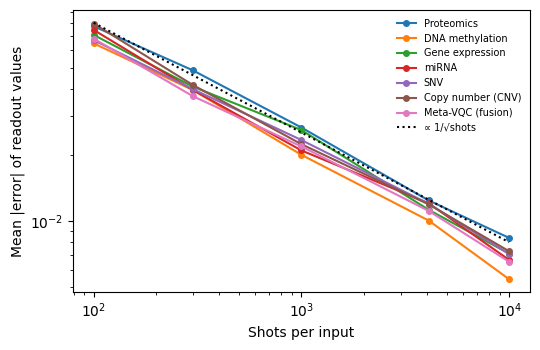

In [8]:
# ============================================================
# 7. FINITE SHOTS: mean absolute error of the readout values vs number of measurement shots
# ============================================================
SHOTS = [100, 300, 1000, 4096, 10000]
rows = []
for c in CIRCS:
    X, T = c.sample_x(40, rng), c.sample_params(40, rng); psi = c.states(X, T); exact = c.expvals(psi)
    for s in SHOTS:
        est = shot_expvals(c, psi, s, rng)
        rows.append({"circuit": c.name, "shots": s, "mean_abs_error": float(np.abs(est - exact).mean()),
                     "max_abs_error": float(np.abs(est - exact).max())})
SH = pd.DataFrame(rows); SH.to_csv(os.path.join(OUTPUT_DIR, "B4_shots.csv"), index=False)
display(SH.pivot(index="shots", columns="circuit", values="mean_abs_error").round(4))
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for c in CIRCS:
    d = SH[SH.circuit == c.name]; ax.loglog(d.shots, d.mean_abs_error, "o-", ms=4, label=c.name)
ax.loglog(SHOTS, [0.8 / np.sqrt(s) for s in SHOTS], "k:", label="∝ 1/√shots")
ax.set_xlabel("Shots per input"); ax.set_ylabel("Mean |error| of readout values"); ax.legend(fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "figB4_shots.png"), dpi=200); plt.show()

Proteomics             done
DNA methylation        done
Gene expression        done
miRNA                  done
SNV                    done
Copy number (CNV)      done
Meta-VQC (fusion)      done


circuit,Copy number (CNV),DNA methylation,Gene expression,Meta-VQC (fusion),Proteomics,SNV,miRNA
p_1q,,,,,,,
0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
0.0001,0.0021,0.0004,0.0028,0.0029,0.0033,0.0037,0.0016
0.0003,0.0065,0.0004,0.0085,0.0086,0.0091,0.0110,0.0043
0.0010,0.0210,0.0016,0.0285,0.0267,0.0270,0.0353,0.0135
0.0030,0.0570,0.0057,0.0704,0.0744,0.0590,0.0937,0.0395
0.0100,0.1383,0.0196,0.1713,0.2155,0.0883,0.2274,0.1152


Each value averages 300 noise trajectories for 32 random inputs; differences below ~0.005 are Monte-Carlo noise.


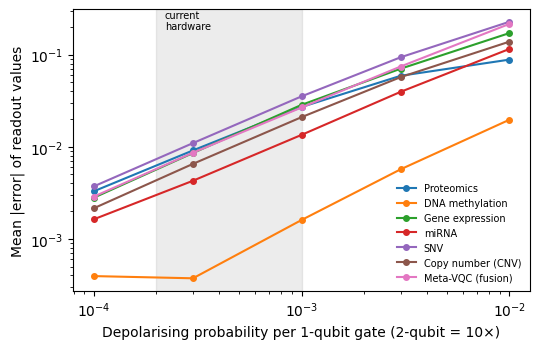

In [9]:
# ============================================================
# 8. NOISE ROBUSTNESS: readout error vs depolarising noise (quantum trajectories)
# p = error probability per qubit after each one-qubit gate; two-qubit gates use 10 p (current IBM devices:
# p ~ 2e-4 to 1e-3 for one-qubit gates, ~ 5e-3 to 1e-2 for two-qubit gates).
# ============================================================
P_LEVELS = [0, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2]
rows = []
for c in CIRCS:
    X, T = c.sample_x(N_NOISE, rng), c.sample_params(N_NOISE, rng); exact = c.expvals(c.states(X, T))
    bs = max(1, int(2 ** 22 / (2 ** c.n * N_TRAJ)))
    for p in P_LEVELS:
        z = np.vstack([noisy_expvals(c, X[i:i + bs], T[i:i + bs], p, N_TRAJ, rng) for i in range(0, len(X), bs)])
        err = np.abs(z - exact)
        rows.append({"circuit": c.name, "p_1q": p, "p_2q": 10 * p, "mean_abs_error": float(err.mean()),
                     "relative_signal_kept": float(np.mean(np.abs(z)) / max(np.mean(np.abs(exact)), 1e-12))})
    print(f"{c.name:22s} done")
NZ = pd.DataFrame(rows); NZ.to_csv(os.path.join(OUTPUT_DIR, "B5_noise.csv"), index=False)
display(NZ.pivot(index="p_1q", columns="circuit", values="mean_abs_error").round(4))
print(f"Each value averages {N_TRAJ} noise trajectories for {N_NOISE} random inputs; differences below ~0.005 are Monte-Carlo noise.")
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for c in CIRCS:
    d = NZ[(NZ.circuit == c.name) & (NZ.p_1q > 0)]; ax.loglog(d.p_1q, d.mean_abs_error, "o-", ms=4, label=c.name)
ax.axvspan(2e-4, 1e-3, color="grey", alpha=0.15); ax.text(2.2e-4, ax.get_ylim()[1] * 0.6, "current\nhardware", fontsize=7)
ax.set_xlabel("Depolarising probability per 1-qubit gate (2-qubit = 10×)"); ax.set_ylabel("Mean |error| of readout values")
ax.legend(fontsize=7, frameon=False); fig.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "figB5_noise.png"), dpi=200); plt.show()

In [10]:
# ============================================================
# 9. QISKIT: compile each circuit to IBM heavy-hex hardware (FakeBrisbane, 127 qubits, native 2-qubit gate ECR)
# ============================================================
def to_qiskit(c, x, t, measure=False):
    from qiskit import QuantumCircuit
    qc = QuantumCircuit(c.n); X, T = x[None], t[None]
    for g in c.gates:
        k, w, a = g[0], g[1], g[2]
        if k == "ry": qc.ry(float(a(X, T)[0]), w[0])
        elif k == "rz": qc.rz(float(a(X, T)[0]), w[0])
        elif k == "rzz": qc.rzz(float(a(X, T)[0]), w[0], w[1])
        elif k == "cz": qc.cz(w[0], w[1])
        elif k == "cnot": qc.cx(w[0], w[1])
    if measure:
        qc.measure_all()
    return qc


def zexp_from_probs_little(c, probs):
    # Qiskit basis index: bit q of the index = qubit q
    idx = np.arange(2 ** c.n); out = []
    for obs in c.readout:
        s = np.ones(2 ** c.n)
        for q in obs:
            s *= 1 - 2 * ((idx >> q) & 1)
        out.append(probs @ s)
    return np.array(out)


TR = None
if RUN_QISKIT:
    from qiskit import transpile
    from qiskit.quantum_info import Statevector
    from qiskit_ibm_runtime.fake_provider import FakeBrisbane
    dev = FakeBrisbane(); rows = []
    for c in CIRCS:
        x, t = c.sample_x(1, rng)[0], c.sample_params(1, rng)[0]
        qc = to_qiskit(c, x, t)
        # the Qiskit circuit must give the same readout values as our simulator
        diff = np.abs(zexp_from_probs_little(c, Statevector(qc).probabilities()) - c.expvals(c.states(x[None], t[None]))[0]).max()
        tq = transpile(qc, backend=dev, optimization_level=3, seed_transpiler=SEED)
        two = sum(1 for ins in tq.data if ins.operation.num_qubits == 2)
        rows.append({"circuit": c.name, "logical_depth": qc.depth(), "logical_2q": sum(1 for ins in qc.data if ins.operation.num_qubits == 2),
                     "hardware_depth": tq.depth(), "hardware_2q_ECR": two, "hardware_ops": dict(tq.count_ops()),
                     "check_vs_simulator": float(diff)})
    TR = pd.DataFrame(rows); TR.to_csv(os.path.join(OUTPUT_DIR, "B6_transpiled_fakebrisbane.csv"), index=False)
    display(TR)
    print("check_vs_simulator ~ 1e-15 means the Qiskit circuits are identical to the ones analysed above.")
    print("More two-qubit gates after compiling = extra SWAPs, because heavy-hex qubits only touch 2-3 neighbours.")
else:
    print("Skipped (Qiskit not available).")

,circuit,logical_depth,logical_2q,hardware_depth,hardware_2q_ECR,hardware_ops,check_vs_simulator
0,Proteomics,30,18,212,54,"{'rz': 209, 'sx': 139, 'ecr': 54, 'x': 8}",3.330669e-16
1,DNA methylation,2,0,4,0,"{'sx': 8, 'rz': 8}",2.220446e-16
2,Gene expression,16,24,161,64,"{'rz': 223, 'sx': 152, 'ecr': 64, 'x': 8}",2.636780e-16
3,miRNA,12,7,25,7,"{'rz': 56, 'sx': 37, 'ecr': 7}",3.330669e-16
4,SNV,15,30,39,30,"{'rz': 138, 'sx': 96, 'ecr': 30, 'x': 6}",5.204170e-16
5,Copy number (CNV),16,12,171,42,"{'rz': 159, 'sx': 119, 'ecr': 42, 'x': 1}",2.775558e-16
6,Meta-VQC (fusion),10,14,27,14,"{'rz': 71, 'sx': 47, 'ecr': 14, 'x': 2}",3.330669e-16


check_vs_simulator ~ 1e-15 means the Qiskit circuits are identical to the ones analysed above.
More two-qubit gates after compiling = extra SWAPs, because heavy-hex qubits only touch 2-3 neighbours.


In [11]:
# ============================================================
# 10. HARDWARE EMULATION: run circuits on noisy IBM fake backends (device noise model: gate errors, T1/T2, readout)
# Compares the readout values from the emulated device with the exact values, for random inputs and parameters.
# FakeManilaV2 (5 qubits) for methylation; FakeLagosV2 (7 qubits) for the 6-qubit circuits; FakeGuadalupeV2 (16 qubits)
# for the 9-qubit gene-expression circuit.
# ============================================================
HW = None
if RUN_QISKIT:
    from qiskit import transpile
    from qiskit_aer import AerSimulator
    from qiskit_ibm_runtime import fake_provider as fp
    jobs = [("DNA methylation", "FakeManilaV2"), ("Proteomics", "FakeLagosV2"), ("Copy number (CNV)", "FakeLagosV2"),
            ("Gene expression", "FakeGuadalupeV2")]
    N_HW, SHOTS_HW = (10, 2048) if FAST else (30, 4096); rows = []
    for name, bk in jobs:
        try:
            backend = getattr(fp, bk)(); sim = AerSimulator.from_backend(backend)
        except Exception as e:
            print(f"{bk} not available ({type(e).__name__}); skipped {name}"); continue
        c = next(cc for cc in CIRCS if cc.name == name); t0 = time.time()
        X, T = c.sample_x(N_HW, rng), c.sample_params(N_HW, rng); exact = c.expvals(c.states(X, T))
        ideal_shots = shot_expvals(c, c.states(X, T), SHOTS_HW, rng)
        circs = [transpile(to_qiskit(c, X[i], T[i], measure=True), sim, optimization_level=3, seed_transpiler=SEED) for i in range(N_HW)]
        res = sim.run(circs, shots=SHOTS_HW, seed_simulator=SEED).result()
        est = []
        for i in range(N_HW):
            cnt = res.get_counts(i); probs = np.zeros(2 ** c.n)
            for bits, v in cnt.items():
                probs[int(bits.replace(" ", ""), 2)] += v
            est.append(zexp_from_probs_little(c, probs / SHOTS_HW))
        est = np.array(est)
        rows.append({"circuit": name, "backend": bk, "inputs": N_HW, "shots": SHOTS_HW,
                     "mean_abs_error_noisy_device": float(np.abs(est - exact).mean()),
                     "mean_abs_error_shots_only": float(np.abs(ideal_shots - exact).mean()),
                     "correlation_with_exact": float(np.corrcoef(est.ravel(), exact.ravel())[0, 1]),
                     "two_qubit_gates_compiled": int(np.mean([sum(1 for ins in q.data if ins.operation.num_qubits == 2) for q in circs]))})
        print(f"{name:22s} on {bk}: {time.time() - t0:.0f}s")
    HW = pd.DataFrame(rows); HW.to_csv(os.path.join(OUTPUT_DIR, "B7_fake_hardware.csv"), index=False); display(HW.round(4))
    print("'shots only' = the error you would get from the same number of shots on a perfect device; the difference to")
    print("'noisy device' is the effect of the hardware noise model. F1 on emulated hardware is computed in Part C.")
else:
    print("Skipped (Qiskit not available).")

DNA methylation        on FakeManilaV2: 1s
Proteomics             on FakeLagosV2: 2s
Copy number (CNV)      on FakeLagosV2: 1s
Gene expression        on FakeGuadalupeV2: 6s


,circuit,backend,inputs,shots,mean_abs_error_noisy_device,mean_abs_error_shots_only,correlation_with_exact,two_qubit_gates_compiled
0,DNA methylation,FakeManilaV2,30,4096,0.0373,0.0087,0.9993,0
1,Proteomics,FakeLagosV2,30,4096,0.0629,0.0131,0.8029,52
2,Copy number (CNV),FakeLagosV2,30,4096,0.1402,0.0112,0.8715,39
3,Gene expression,FakeGuadalupeV2,30,4096,0.0585,0.0099,0.9929,58


'shots only' = the error you would get from the same number of shots on a perfect device; the difference to
'noisy device' is the effect of the hardware noise model. F1 on emulated hardware is computed in Part C.


In [12]:
# ============================================================
# 11. SUMMARY LINES FOR THE REPORT
# ============================================================
def line(s): print("•", s)


for c in CIRCS:
    r = RES[RES.circuit == c.name].iloc[0]; e = EXP[(EXP.circuit == c.name) & (EXP.variant == "with entangling gates")].iloc[0]
    ne = EXP[(EXP.circuit == c.name) & (EXP.variant == "without entangling gates")]
    s = (f"{c.name}: {c.n} qubits, {r.quantum_params} circuit + {r.total_params - r.quantum_params} readout parameters, "
         f"{r.two_qubit_gates} two-qubit gates, depth {r.depth}; frame-potential ratio {e.frame_potential_ratio:.2f}, "
         f"entangling capability Q = {abs(e.entangling_capability_Q):.3f}")
    if len(ne):
        s += f" (without entangling gates: ratio {ne.frame_potential_ratio.values[0]:.2f}, Q = 0)"
    line(s + ".")
for cost in ["local", "global"]:
    ratios = []
    for fam in FAMILIES:
        d = BP[(BP.family == fam) & (BP.cost == cost) & ~BP.structural_zero].set_index("qubits").grad_variance
        if min(QUBITS) in d and max(QUBITS) in d:
            ratios.append((fam, d[min(QUBITS)] / d[max(QUBITS)]))
    line(f"{cost.capitalize()}-cost gradient variance fell from {min(QUBITS)} to {max(QUBITS)} qubits by a factor of " +
         ", ".join(f"{f} {r:.0f}x" for f, r in ratios) + ".")
w = NZ[NZ.p_1q == 1e-3]
line(f"At hardware-like noise (p = 1e-3 one-qubit, 1e-2 two-qubit) the mean readout error ranged "
     f"{w.mean_abs_error.min():.3f}–{w.mean_abs_error.max():.3f} across circuits.")
if TR is not None:
    line("On FakeBrisbane (heavy-hex) the circuits compile to " +
         ", ".join(f"{r.circuit} {r.hardware_2q_ECR} ECR / depth {r.hardware_depth}" for r in TR.itertuples()) + ".")
if HW is not None and len(HW):
    line("Emulated hardware: " + "; ".join(f"{r.circuit} on {r.backend} mean error {r.mean_abs_error_noisy_device:.3f} "
                                          f"(shots only {r.mean_abs_error_shots_only:.3f})" for r in HW.itertuples()) + ".")
print("\nFiles:", sorted(os.listdir(OUTPUT_DIR)))

• Proteomics: 6 qubits, 54 circuit + 28 readout parameters, 18 two-qubit gates, depth 30; frame-potential ratio 0.99, entangling capability Q = 0.943 (without entangling gates: ratio 3.10, Q = 0).
• DNA methylation: 4 qubits, 4 circuit + 44 readout parameters, 0 two-qubit gates, depth 2; frame-potential ratio 2.62, entangling capability Q = 0.000.
• Gene expression: 9 qubits, 27 circuit + 40 readout parameters, 24 two-qubit gates, depth 16; frame-potential ratio 2.91, entangling capability Q = 0.771 (without entangling gates: ratio 6.58, Q = 0).
• miRNA: 8 qubits, 48 circuit + 36 readout parameters, 7 two-qubit gates, depth 12; frame-potential ratio 2.29, entangling capability Q = 0.494 (without entangling gates: ratio 5.75, Q = 0).
• SNV: 11 qubits, 66 circuit + 48 readout parameters, 30 two-qubit gates, depth 15; frame-potential ratio 5.43, entangling capability Q = 0.653 (without entangling gates: ratio 16.05, Q = 0).
• Copy number (CNV): 6 qubits, 30 circuit + 52 readout parameters